# 03: Model Değerlendirme Fonksiyonları (Kişi 3)

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini

**Bu notebook'ta yapılanlar:**
1. İnme tahmini için hangi metriklerin neden kullanıldığı
2. Model değerlendirme yönteminin belirlenmesi: çapraz doğrulama, eşik seçimi, test seti
3. Ekibin ortak kullanacağı değerlendirme fonksiyonlarının yazılması (`src/metrics.py`)
4. Fonksiyonların model eğitimi sırasında ve sonrasında nasıl çağrılacağı

## 1. Kurulum

Ek kurulum gerekmez: fonksiyonlar yalnızca `numpy`, `pandas`, `matplotlib` ve `scikit-learn` kullanır (Colab'da hazır gelir). SMOTE'lu pipeline kullanılacaksa `imbalanced-learn` gerekir, o da Colab'da yüklüdür. Colab'da `config.py` ve `metrics.py` dosyalarını (pipeline için `preprocessing.py`) sol menüdeki klasör simgesinden yükleyin.

## 2. Hangi metrikler, neden?

Veride inme geçiren kişiler azınlıktadır. Bu yüzden **accuracy (doğruluk) yanıltıcıdır**: örneğin inme oranı %10 olsaydı, herkese "inme yok" diyen ve hiçbir vakayı yakalamayan bir model %90 doğruluk alırdı. Modeller bu nedenle aşağıdaki metriklerle değerlendirilir.

| Metrik | Soru | İnme açısından anlamı |
|---|---|---|
| **Recall** (duyarlılık) | Gerçek inme vakalarının yüzde kaçını yakaladık? | En önemli metrik: kaçırılan her vaka, uyarılmamış bir hasta demektir |
| **Precision** (kesinlik) | "İnme riski var" dediklerimizin yüzde kaçı gerçekten inme geçirdi? | Düşükse çok yanlış alarm var: gereksiz tetkik ve endişe |
| **Specificity** (özgüllük) | İnme geçirmeyenlerin yüzde kaçına doğru "yok" dedik? | Sağlıklı kişileri gereksiz yere riskli saymama oranı |
| **F1** | Recall ve precision'ın harmonik ortalaması | İkisini tek sayıda dengeler |
| **ROC-AUC** | Model inme geçirecek birini geçirmeyecek birinden daha riskli sıralıyor mu? | Eşikten bağımsız, genel ayırt etme gücü |
| **PR-AUC** | Tüm eşiklerde recall ve precision birlikte ne kadar iyi? | Eşikten bağımsız, azınlık sınıfa odaklı |
| Accuracy | Tüm tahminlerin yüzde kaçı doğru? | Yalnızca karşılaştırma için raporlanır, model seçiminde kullanılmaz |

### Neden ana metrik PR-AUC?

- **Recall tek başına seçim metriği olamaz:** herkese "inme var" diyen bir model recall = 1 alır. Recall, precision ile birlikte okunmalıdır.
- **ROC-AUC dengesiz veride iyimserdir:** yanlış alarm oranını, sayıca çok fazla olan sağlıklı kişilere bölerek hesaplar. Yüzlerce yanlış alarm bile bu oranı az değiştirir, eğri iyi görünür.
- **PR-AUC** doğrudan azınlık sınıfa (inme) bakar: yanlış alarmlar precision'ı hemen düşürür. Rastgele bir modelin PR-AUC'si inme oranına eşittir, bu da kıyas için net bir taban verir.

Bu yüzden hiperparametre aramasında en iyi model **PR-AUC** ile seçilir (`MAIN_METRIC`), ardından karar eşiği istenen recall'a göre ayarlanır.

### Değerlendirme yöntemi

- **Çapraz doğrulama (5 katlı, katmanlı, sabit seed):** model seçimi ve hiperparametre araması yalnızca eğitim verisi üzerinde yapılır. Her kat bir kez doğrulama verisi olur, skorlar ortalama ± standart sapma olarak raporlanır. Veri küçük olduğu için standart sapma önemlidir: iki model arasındaki fark bu sapmadan küçükse, aralarında gerçek bir fark olduğu söylenemez.
- **Eğitim - CV farkı:** her katta eğitim skoru da hesaplanır. Eğitim skoru doğrulama skorundan çok yüksekse model eğitim verisini ezberlemiştir (overfitting).
- **Eşik seçimi:** modeller varsayılan olarak olasılık ≥ 0.5 ise "inme var" der. Dengesiz veride bu eşik çok vakayı kaçırır. Eşik, CV tahminleri üzerinde hedef recall'u (varsayılan %80, `TARGET_RECALL`) en az yanlış alarmla sağlayacak şekilde seçilir.
- **Test seti en sona kadar kullanılmaz:** model ve eşik seçimi bittikten sonra final model test setinde **bir kez** değerlendirilir. Test setine bakarak yapılan her seçim, test skorunu yapay olarak iyileştirir.

## 3. Ortak değerlendirme fonksiyonu

Fonksiyonlar `src/metrics.py` dosyasındadır, ortak sabitler (`RANDOM_STATE`, `CV_FOLDS`, `MAIN_METRIC`, `TARGET_RECALL`, `RESULTS_FILE`) `src/config.py`'de. **Ekipteki herkes** bunları kendi notebook'una import edip kullanır:

```python
from metrics import cv_evaluate
result = cv_evaluate(model, X_train, y_train, model_name="SVM")
```

**Ekibe notlar:**
- Model düz bir model ya da pipeline olabilir (ör. `build_pipeline()` çıktısı). **SMOTE mutlaka pipeline içinde olmalı**, SMOTE'lanmış veri dosyaya kaydedilip onunla CV yapılmamalı: aksi halde sentetik örnekler doğrulama katına sızar ve recall gerçekte olduğundan yüksek çıkar.
- Fonksiyonlar modelden bağımsızdır. Model `predict_proba` desteklemiyorsa (ör. `SVC(probability=False)`) `decision_function` kullanılır.
- Herkes aynı CV katlarını (`shared_cv()`) ve aynı metrikleri (`SCORING`) kullanır, böylece modellerin sonuçları birbiriyle karşılaştırılabilir.
- Her `cv_evaluate` çağrısı `results.csv` dosyasına bir satır ekler. Karşılaştırma tablosu bu dosyadan çıkar.
- Rastgelelik içeren her adımda (`SMOTE`, `RandomForestClassifier`, `SVC`...) `random_state=RANDOM_STATE` verilmelidir. Aksi halde her çalıştırmada farklı sonuç çıkar.

In [1]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

from config import MAIN_METRIC, RANDOM_STATE, TARGET_RECALL
from metrics import (SCORING, compare_models, cv_evaluate, learning_curve_analysis, plot_curves,
                     shared_cv, test_evaluate, threshold_analysis)

## 4. Fonksiyonların içindeki adımlar

| Fonksiyon | Ne yapar | Ne döndürür |
|---|---|---|
| `shared_cv()`, `SCORING`, `MAIN_METRIC` | Ortak CV katları ve metrikler. Hiperparametre aramasına verilir | `StratifiedKFold`, metrik sözlüğü, `"pr_auc"` |
| `cv_evaluate(model, X_train, y_train, model_name)` | Modeli 5 katta sıfırdan eğitir, her katta eğitim ve doğrulama skorlarını hesaplar, sonucu `results.csv`'ye ekler | Metrik özeti (`summary`: eğitim ort., CV ort., CV std, fark), kat sonuçları (`folds`), CV tahminleri (`oof_score`) |
| `threshold_analysis(y, oof_score, target_recall)` | Eşiğe göre yakalanan vaka, kaçırılan vaka, yanlış alarm tablosu; hedef recall'u sağlayan en yüksek eşiği seçer | `(table, chosen_threshold)` |
| `learning_curve_analysis(model, X_train, y_train)` | Eğitim verisi büyüdükçe eğitim ve CV skorunu çizer | Boyut / skor tablosu |
| `test_evaluate(model, X_test, y_test, threshold)` | Final modeli test setinde bir kez değerlendirir: karmaşıklık matrisi, ROC ve PR eğrileri, CV ile test farkı | Test metrikleri, karmaşıklık matrisi, test skorları |
| `compare_models()` | `results.csv`'deki tüm modelleri tablo ve grafiklerle karşılaştırır | Model × metrik tablosu |
| `plot_curves({name: (y, score)})` | Birden fazla modelin ROC ve PR eğrilerini aynı grafikte çizer | (grafik) |

**OOF (out-of-fold) tahmini nedir?** CV'de her eğitim satırı tam olarak bir kez doğrulama katına düşer. O satırın skoru, onu hiç görmemiş modelden gelir. Böylece test setine dokunmadan, tüm eğitim verisi için "görülmemiş veri" tahmini elde edilir. Eşik bu tahminlerle seçilir.

## 5. Ekip için kullanım

Her ekip üyesi kendi model notebook'unda şu adımları uygular.

**1) Hiperparametre araması: ortak katlar ve ortak metriklerle**

```python
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from config import MAIN_METRIC
from metrics import SCORING, shared_cv
from preprocessing import build_pipeline, load_data

X_train, X_test, y_train, y_test = load_data()
model = build_pipeline(SVC(probability=True), balancing="smote")
search = GridSearchCV(model, {"model__C": [0.1, 1, 10]}, cv=shared_cv(),
                      scoring=SCORING, refit=MAIN_METRIC, n_jobs=-1)
search.fit(X_train, y_train)
best = search.best_estimator_
```

**2) En iyi modelin CV değerlendirmesi, eşik ve overfitting kontrolü**

```python
from metrics import cv_evaluate, threshold_analysis, learning_curve_analysis

result = cv_evaluate(best, X_train, y_train, model_name="SVM",
                     note="SMOTE + SVM, C araması")
table, threshold = threshold_analysis(result["y"], result["oof_score"], model_name="SVM")
learning_curve_analysis(best, X_train, y_train, model_name="SVM")
```

**3) Final: test seti (yalnızca en sonda, bir kez)**

```python
from metrics import test_evaluate

best.fit(X_train, y_train)                     # tüm eğitim verisiyle
test = test_evaluate(best, X_test, y_test, threshold=threshold,
                     model_name="SVM", cv_result=result)
```

**4) Tüm modellerin karşılaştırılması** (herkes `results.csv`'ye satır ekledikten sonra):

```python
from metrics import compare_models, plot_curves

compare_models("results.csv")
plot_curves({"Logistic Regression": (lr_result["y"], lr_result["oof_score"]),
             "SVM": (svm_result["y"], svm_result["oof_score"]),
             "Random Forest": (rf_result["y"], rf_result["oof_score"])})
```

Aynı eğitilmiş model XAI için de doğrudan kullanılabilir: `explain(best, X_train, X_test, model_name="SVM")` (`src/explain.py`).

## 6. Tasarım seçimleri neden böyle? (sayılarla)

Ortak değerlendirme düzeninde sabit duran değerler (bölme oranı, seed, kat sayısı, ana metrik, recall hedefi, eşik yöntemi) "herkes böyle yapıyor" diye seçilmedi. Bu bölüm her birini **tek bir referans model** üzerinde karşılaştırır.

**Referans model:** Random Forest, dengeleme yok, `max_depth=3`, `min_samples_leaf=40`, `max_features="sqrt"`, `n_estimators=300`, `random_state=RANDOM_STATE` (ekibin şu anki en iyi ayarlı yapılandırması). Pipeline `build_pipeline(model, balancing="none")` ile kurulur.

**Kurallar:**
- Resmi bölme (%80/%20, `RANDOM_STATE=42`) değişmez. Alt bölüm 6.1'deki farklı oranlar yalnızca bu çalışmanın içinde, train + test birleştirilerek denenir.
- Diğer alt bölümler yalnızca eğitim seti (yaklaşık 3521 kişi) üzerinde, `cv_evaluate` ve `threshold_analysis` ile çalışır; test setine bakılmaz.
- Farklar gürültü sınırı içindeyse bunu açıkça yazıyoruz.

In [2]:
import contextlib, io, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split

from config import CV_FOLDS, TEST_SIZE
from metrics import compute_metrics, predict_score
from preprocessing import build_pipeline, load_data

X_train, X_test, y_train, y_test = load_data()
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

ref_rf = RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=40,
                                max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
ref_model = build_pipeline(ref_rf, balancing="none")


def cv_run(model, n_splits=CV_FOLDS, seed=RANDOM_STATE, threshold=0.5):
    """cv_evaluate on the training set with a chosen fold count / shuffle seed; nothing is saved."""
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return cv_evaluate(model, X_train, y_train, cv=cv, threshold=threshold, save=False, verbose=False)


print(f"Eğitim: {len(y_train)} kişi, inme {int(y_train.sum())} (%{y_train.mean():.1%})")
print(f"Test:   {len(y_test)} kişi, inme {int(y_test.sum())} (%{y_test.mean():.1%})")
print(f"Birleşik: {len(y_all)} kişi, inme {int(y_all.sum())} (%{y_all.mean():.1%})")

Eğitim: 3521 kişi, inme 306 (%8.7%)
Test:   881 kişi, inme 77 (%8.7%)
Birleşik: 4402 kişi, inme 383 (%8.7%)


### 6.1 Bölme oranı: 70/30, 80/20, 90/10

Soru: test seti ne kadar büyük olmalı? Test büyüdükçe skor daha güvenilir olur, ama eğitim verisi azalır. İnme oranı yaklaşık %8,7 olduğu için küçük bir test setinde çok az inme vakası kalır ve skor büyük ölçüde şansa bağlı olur.

Yöntem: train + test birleştirilir, her oran için 20 farklı seed ile katmanlı bölme yapılır, referans model eğitilir, test PR-AUC ve ROC-AUC hesaplanır. Seedler arası standart sapma, "aynı model farklı şanslı/şanssız bölmede ne kadar oynuyor?" sorusunun cevabıdır.

20 seed x 3 oran, referans model, test seti metrikleri

       n_test  test_strokes  pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  recall_sd_at_0.80
90/10   441.0          38.0        0.199       0.043         0.713        0.042              0.065
80/20   881.0          77.0        0.212       0.033         0.721        0.028              0.046
70/30  1321.0         115.0        0.208       0.025         0.721        0.023              0.037


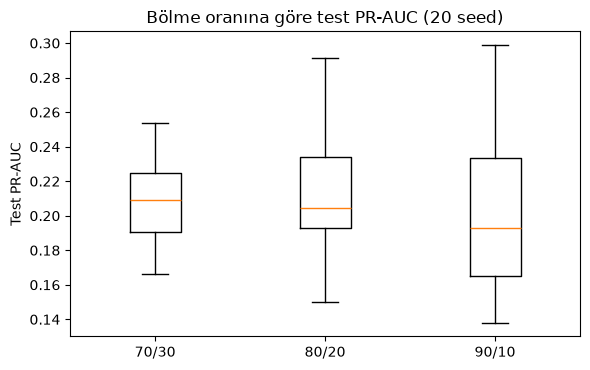

In [3]:
SPLIT_SEEDS = range(20)
rows = []
for test_size in (0.30, 0.20, 0.10):
    for seed in SPLIT_SEEDS:
        Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=test_size,
                                          stratify=y_all, random_state=seed)
        model = clone(ref_model).fit(Xa, ya)
        m = compute_metrics(yb, predict_score(model, Xb))
        rows.append({"test_size": test_size, "seed": seed, "n_test": len(yb),
                     "test_strokes": int(yb.sum()), "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"]})
split_runs = pd.DataFrame(rows)

split_summary = split_runs.groupby("test_size").agg(
    n_test=("n_test", "mean"), test_strokes=("test_strokes", "mean"),
    pr_auc_mean=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
    roc_auc_mean=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"))
# Recall'un tek başına örnekleme belirsizliği: hedef recall 0.80 iken binom standart hatası
split_summary["recall_sd_at_0.80"] = np.sqrt(0.8 * 0.2 / split_summary["test_strokes"])
split_summary.index = [f"{int((1 - t) * 100)}/{int(t * 100)}" for t in split_summary.index]
print(f"{len(SPLIT_SEEDS)} seed x 3 oran, referans model, test seti metrikleri\n")
print(split_summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3.8))
data = [split_runs.loc[split_runs.test_size == t, "pr_auc"] for t in (0.30, 0.20, 0.10)]
ax.boxplot(data, tick_labels=["70/30", "80/20", "90/10"])
ax.set_ylabel("Test PR-AUC")
ax.set_title("Bölme oranına göre test PR-AUC (20 seed)")
plt.tight_layout()
plt.show()

**Okuma:** PR-AUC ortalaması üç oranda da yaklaşık aynı (0,20-0,21); oranlar arasındaki fark ortalamada değil, **oynaklıkta**. Test setindeki inme sayısı 115 / 77 / 38 iken PR-AUC standart sapması 0,025 / 0,033 / 0,043. Yani %10'luk test setinde sadece ~38 inme var ve aynı model şansa göre çok farklı skor alıyor; recall'un tek başına örnekleme hatası bile hedef 0,80 iken ±0,065'e çıkıyor. 70/30, 80/20'den biraz daha kararlı (0,025'e karşı 0,033), ama eğitim verisini %12,5 azaltıyor ve ortalama PR-AUC'de kazanç görünmüyor. Bu std, hem bölmenin hem de o bölmeyle eğitilen modelin değişkenliğini içerir.

**Seçim: 80/20, çünkü %90/10'daki ~38 inmelik test seti güvenilmez, 70/30'un ek kararlılığı ise eğitim verisinden vazgeçmeye değecek kadar büyük değil. 80/20 ile 70/30 arasındaki fark gürültü sınırına yakın, yani bu bir ara değer tercihidir, kesin kazanan değil.**

### 6.2 Seed kararlılığı

Soru: CV katlarının karıştırılma seed'i sonucu ne kadar değiştiriyor? `RANDOM_STATE=42` "şanslı bir seed" mi, yoksa seçim fark etmiyor mu? 10 farklı seed ile aynı 5 katlı CV tekrarlanır (modelin kendi `random_state`'i sabit).

In [4]:
seed_rows = []
for seed in range(10):
    s = cv_run(ref_model, seed=seed)["summary"]
    seed_rows.append({"seed": seed, "pr_auc_cv": s.loc["pr_auc", "cv_mean"],
                      "pr_auc_fold_std": s.loc["pr_auc", "cv_std"],
                      "roc_auc_cv": s.loc["roc_auc", "cv_mean"]})
seed_df = pd.DataFrame(seed_rows).set_index("seed")
print(seed_df.round(4).to_string())
print(f"\nPR-AUC (CV ortalaması): seedler arası ortalama {seed_df.pr_auc_cv.mean():.4f}, "
      f"std {seed_df.pr_auc_cv.std():.4f}, aralık {seed_df.pr_auc_cv.min():.4f} - {seed_df.pr_auc_cv.max():.4f}")
print(f"Aynı seed içinde katlar arası std (ortalama): {seed_df.pr_auc_fold_std.mean():.4f}")
print(f"RANDOM_STATE={RANDOM_STATE} için PR-AUC: {cv_run(ref_model)['summary'].loc['pr_auc', 'cv_mean']:.4f}")

      pr_auc_cv  pr_auc_fold_std  roc_auc_cv
seed                                        
0        0.2085           0.0231      0.7080
1        0.2122           0.0299      0.7083
2        0.2084           0.0375      0.7103
3        0.2069           0.0235      0.7134
4        0.2038           0.0239      0.7112
5        0.2077           0.0441      0.7094
6        0.2110           0.0389      0.7132
7        0.2063           0.0325      0.7158
8        0.2113           0.0575      0.7120
9        0.2147           0.0752      0.7107

PR-AUC (CV ortalaması): seedler arası ortalama 0.2091, std 0.0032, aralık 0.2038 - 0.2147
Aynı seed içinde katlar arası std (ortalama): 0.0386


RANDOM_STATE=42 için PR-AUC: 0.2214


**Okuma:** 10 seed boyunca CV PR-AUC ortalaması 0,209, std yalnızca 0,003 (aralık 0,204-0,215); aynı seed içinde katlar arası std ise 0,039, yani seed etkisi kat etkisinin yaklaşık 10 katı küçük. Dikkat: `RANDOM_STATE=42` bu aralığın **üstünde** (0,221, ortalamanın yaklaşık 3,8 std üzerinde). Yani 42 ile raporlanan mutlak PR-AUC ~0,01 iyimser; modeller aynı katlarla karşılaştırıldığı için sıralama adil kalır, ama mutlak skoru "0,22" diye sunmak yerine "~0,21 ± 0,01 (seed'e göre)" demek daha dürüst.

**Seçim: seed sabit tutulur (tekrarlanabilirlik için), çünkü seed etkisi küçük (std 0,003) ve model sıralamasını bozmaz; ancak mutlak skor raporlanırken seed aralığı not edilir.**

### 6.3 Kat sayısı: 3, 5, 10

Soru: kat sayısı arttıkça tahmin daha az kötümser olur (eğitim verisi büyür) ama süre artar. Her kat sayısı 5 farklı seed ile tekrarlanır: ortalama PR-AUC, seedler arası std (tekrarlanabilirlik), kat başı std ve toplam süre.

In [5]:
fold_rows = []
for k in (3, 5, 10):
    means, fold_stds, t0 = [], [], time.perf_counter()
    for seed in range(5):
        s = cv_run(ref_model, n_splits=k, seed=seed)["summary"]
        means.append(s.loc["pr_auc", "cv_mean"])
        fold_stds.append(s.loc["pr_auc", "cv_std"])
    elapsed = (time.perf_counter() - t0) / 5
    fold_rows.append({"katlar": k, "pr_auc_ort": np.mean(means), "seedler_arasi_std": np.std(means, ddof=1),
                      "kat_ici_std": np.mean(fold_stds), "sure_sn_(tek CV)": elapsed})
fold_df = pd.DataFrame(fold_rows).set_index("katlar")
print(fold_df.round(4).to_string())

        pr_auc_ort  seedler_arasi_std  kat_ici_std  sure_sn_(tek CV)
katlar                                                              
3           0.2005             0.0056       0.0204            0.6666
5           0.2080             0.0030       0.0276            1.1512
10          0.2212             0.0037       0.0541            4.3897


**Okuma:** 3 kat 0,2005, 5 kat 0,2080, 10 kat 0,2212: kat sayısı arttıkça PR-AUC yükseliyor (eğitim verisi büyüdüğü için tahmin daha az kötümser), yani kat sayıları arasında **mutlak skor kıyaslanamaz**, ortak olarak tek bir sayı seçmek bu yüzden gerekli. Seedler arası std 3 katta 0,0056, 5 katta 0,0030, 10 katta 0,0037: 5 ve 10 arasındaki fark gürültü sınırında. Katlar arası std ise 10 katta 0,054 (her doğrulama katında ~31 inme), 5 katta 0,028. Süre: 5 kat 1,2 sn, 10 kat 4,4 sn (yaklaşık 4 kat, bu çalışmadaki makinede).

**Seçim: 5 kat, çünkü 3 katın tekrarlanabilirliği daha kötü (std 0,0056), 10 kat ise 5 katla aynı kararlılıkta olup (0,0037 ile 0,0030 gürültü içinde) bu kadar küçük kat başına inme sayısıyla daha oynak ve çok daha yavaş (hiperparametre aramasında bu fark katlanır).**

### 6.4 Ana metrik: accuracy neden yanıltır, PR-AUC neden seçildi?

**(a) Accuracy.** Herkese "inme yok" diyen bir model:

In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
m = compute_metrics(y_test, predict_score(dummy, X_test)) if hasattr(dummy, "predict_proba") else None
print(f"Çoğunluk sınıfı modeli (test seti, {int(y_test.sum())} inme): "
      f"accuracy {m['accuracy']:.3f}, recall {m['recall']:.3f}, precision {m['precision']:.3f}, PR-AUC {m['pr_auc']:.3f}")
ref_cv = cv_run(ref_model)
print(f"Referans RF (CV): accuracy {ref_cv['summary'].loc['accuracy', 'cv_mean']:.3f}, "
      f"recall@0.5 {ref_cv['summary'].loc['recall', 'cv_mean']:.3f}, PR-AUC {ref_cv['summary'].loc['pr_auc', 'cv_mean']:.3f}")

Çoğunluk sınıfı modeli (test seti, 77 inme): accuracy 0.913, recall 0.000, precision 0.000, PR-AUC 0.087


Referans RF (CV): accuracy 0.913, recall@0.5 0.000, PR-AUC 0.221


**(b) Metrik seçimi kazananı değiştiriyor mu?** Birbirinden gerçekten farklı davranan 7 aday yapılandırma aynı CV ile ölçülür. F1 ve recall eşik gerektirdiği için varsayılan eşik 0.5 ile hesaplanır; ROC-AUC ve PR-AUC eşikten bağımsızdır. Her metrikte kazanan (1. sıra) ve PR-AUC sıralamasıyla uyum (Spearman) gösterilir.

In [7]:
candidates = {
    "RF ayarlı (referans)": ref_model,
    "RF ayarlı + class_weight": build_pipeline(clone(ref_rf), balancing="class_weight"),
    "RF derin (depth=None), dengeleme yok": build_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), balancing="none"),
    "RF derin (depth=None) + class_weight": build_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), balancing="class_weight"),
    "RF depth=6 + SMOTE": build_pipeline(
        RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1),
        balancing="smote"),
    "LogReg": build_pipeline(LogisticRegression(max_iter=2000), balancing="none"),
    "LogReg + class_weight": build_pipeline(LogisticRegression(max_iter=2000), balancing="class_weight"),
}
metric_rows = {}
for name, model in candidates.items():
    s = cv_run(model)["summary"]["cv_mean"]
    metric_rows[name] = s[["accuracy", "recall", "f1", "roc_auc", "pr_auc"]]
cand = pd.DataFrame(metric_rows).T
print(cand.round(3).to_string())

ranks = cand.rank(ascending=False).astype(int)
print("\nSıralama (1 = en iyi):")
print(ranks.to_string())
print("\nMetrik başına kazanan:")
for c in cand.columns:
    print(f"  {c:9s}: {cand[c].idxmax()}  ({cand[c].max():.3f})")
print("\nPR-AUC sıralamasıyla Spearman uyumu:")
print(cand.corr(method="spearman")["pr_auc"].drop("pr_auc").round(2).to_string())

metric                                accuracy  recall     f1  roc_auc  pr_auc
RF ayarlı (referans)                     0.913   0.000  0.000    0.712   0.221
RF ayarlı + class_weight                 0.670   0.595  0.238    0.712   0.212
RF derin (depth=None), dengeleme yok     0.912   0.007  0.013    0.678   0.175
RF derin (depth=None) + class_weight     0.900   0.062  0.097    0.697   0.173
RF depth=6 + SMOTE                       0.764   0.454  0.250    0.703   0.188
LogReg                                   0.913   0.007  0.013    0.717   0.199
LogReg + class_weight                    0.666   0.627  0.246    0.715   0.200

Sıralama (1 = en iyi):
metric                                accuracy  recall  f1  roc_auc  pr_auc
RF ayarlı (referans)                         2       7   7        4       1
RF ayarlı + class_weight                     6       2   3        3       2
RF derin (depth=None), dengeleme yok         3       6   5        7       6
RF derin (depth=None) + class_weight    

**Okuma:** (a) Hiçbir inmeyi yakalamayan çoğunluk modeli test setinde %91,3 accuracy alıyor; ayarlı RF de CV'de aynı %91,3'te (eşik 0,5'te recall 0). Accuracy iki modeli ayıramıyor. (b) Metriğe göre kazanan değişiyor: accuracy ve ROC-AUC'de LogReg, recall'da class_weight'li LogReg, F1'de SMOTE'lu RF, PR-AUC'de ayarlı RF kazanıyor, yani 4 farklı model. Recall ve F1 modelin skor sıralamasını değil, o modelin 0,5 eşiğinde ne kadar "cesur" davrandığını ölçüyor (PR-AUC sıralamasıyla Spearman 0,04 ve -0,18), bu yüzden class_weight'li modeller öne çıkıyor ama bu ayar zaten sonradan eşik seçimiyle yapılabilir. Accuracy da PR-AUC ile uyumsuz (-0,07). ROC-AUC ile uyum daha yüksek (0,61), ve ROC-AUC kazananı (LogReg 0,717) ayarlı RF'den (0,712) yalnızca 0,005 önde, bu fark gürültü içinde. ROC-AUC bu veride pozitif sınıfın azlığına duyarsız olduğu için modelleri PR-AUC kadar ayıramıyor (ROC-AUC aralığı 0,68-0,72, PR-AUC aralığı 0,17-0,22).

**Seçim: PR-AUC, çünkü accuracy yanıltıcı, F1 ve recall eşik seçimine bağlı (modelin sıralama kalitesini değil 0,5 eşiğindeki davranışını ölçüyor) ve ROC-AUC modeller arası farkı daha az gösteriyor. Not: PR-AUC ile ROC-AUC kazananı arasındaki fark çok küçük; PR-AUC'nin üstünlüğü büyük bir fark değil, azınlık sınıfa odaklanması ve eşikten bağımsız olması gerekçesidir.**

### 6.5 Recall hedefi: 0.70 / 0.80 / 0.90

Soru: eşik, hangi recall hedefini sağlayacak şekilde seçilmeli? Referans modelin CV tahminleri (OOF, test setine bakılmaz) üzerinde `threshold_analysis` ile her hedef için eşik ve bedeli hesaplanır.

In [8]:
oof = ref_cv
y_oof, s_oof = oof["y"], oof["oof_score"]

def at_threshold(thr):
    m = compute_metrics(y_oof, s_oof, thr)
    fp_per_1000 = (1 - m["specificity"]) * (y_oof == 0).sum() / len(y_oof) * 1000
    caught = m["recall"] * y_oof.sum()
    return {"esik": thr, "recall": m["recall"], "precision": m["precision"], "f1": m["f1"],
            "yakalanan_inme": f"{caught:.0f}/{int(y_oof.sum())}", "yanlis_alarm_/1000": fp_per_1000,
            "alarm_basina_gercek_inme": m["precision"]}

target_rows = {}
for target in (0.70, 0.80, 0.90):
    with contextlib.redirect_stdout(io.StringIO()):
        _, thr = threshold_analysis(y_oof, s_oof, target_recall=target, plot=False)
    target_rows[f"recall >= {target:.2f}"] = at_threshold(thr)
target_df = pd.DataFrame(target_rows).T.drop(columns="alarm_basina_gercek_inme")
print(f"OOF: {len(y_oof)} kişi, {int(y_oof.sum())} inme\n")
print(target_df.to_string(float_format=lambda v: f"{v:.3f}"))

OOF: 3521 kişi, 306 inme

                esik recall precision    f1 yakalanan_inme yanlis_alarm_/1000
recall >= 0.70 0.081  0.703     0.142 0.237        215/306            367.793
recall >= 0.80 0.068  0.801     0.132 0.227        245/306            456.404
recall >= 0.90 0.050  0.902     0.114 0.202        276/306            610.338


**Okuma:** Hedef 0,70 / 0,80 / 0,90 için eşik 0,081 / 0,068 / 0,050 ve 1000 kişide yanlış alarm 368 / 456 / 610. Precision hepsinde düşük (0,142 / 0,132 / 0,114): bu modelle (ROC-AUC ~0,71) her yüksek recall hedefi, çok sayıda yanlış alarm demek. 0,70'ten 0,80'e geçiş 30 inme daha yakalatıyor (215'ten 245'e) ve 1000 kişide 89 yanlış alarm ekliyor; 0,80'den 0,90'a geçiş 31 inme daha için 154 yanlış alarm ekliyor, yani her ek inme giderek pahalılaşıyor. Veri bu aşamada "doğru" hedefi kendisi söylemiyor; hedef klinik/maliyet kararıdır.

**Seçim: 0,80, çünkü 0,70 her on inmeden üçünü kaçırıyor ve 0,90'ın marjinal yanlış alarm bedeli (31 inme için 154/1000) 0,70→0,80 geçişinden (30 inme için 89/1000) belirgin biçimde yüksek. Bu, verinin tek başına kanıtladığı bir optimum değil, görünür bir ödünleşimde yapılmış bir politika tercihidir.**

### 6.6 Eşik yöntemi

Soru: aynı OOF skorlarında dört eşik yönteminin sonucu nedir? (1) recall hedefi 0.80, (2) Youden J (recall + specificity - 1 en büyük), (3) F1'i en büyük yapan eşik, (4) sabit 0.5.

In [9]:
fpr, tpr, roc_thr = roc_curve(y_oof, s_oof)
youden_thr = float(roc_thr[np.argmax(tpr - fpr)])

prec, rec, pr_thr = precision_recall_curve(y_oof, s_oof)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
f1_thr = float(pr_thr[np.argmax(f1)])

with contextlib.redirect_stdout(io.StringIO()):
    _, recall_thr = threshold_analysis(y_oof, s_oof, target_recall=0.80, plot=False)

method_rows = {"Recall hedefi 0.80": at_threshold(recall_thr),
               "Youden J": at_threshold(youden_thr),
               "Maks. F1": at_threshold(f1_thr),
               "Sabit 0.5": at_threshold(0.5)}
method_df = pd.DataFrame(method_rows).T.drop(columns="alarm_basina_gercek_inme")
print(method_df.to_string(float_format=lambda v: f"{v:.3f}"))

                    esik recall precision    f1 yakalanan_inme yanlis_alarm_/1000
Recall hedefi 0.80 0.068  0.801     0.132 0.227        245/306            456.404
Youden J           0.077  0.748     0.142 0.239        229/306            391.934
Maks. F1           0.123  0.435     0.187 0.262        133/306            164.158
Sabit 0.5          0.500  0.000     0.000 0.000          0/306              0.000


**Okuma:** Sabit 0,5 eşiği bu modelde (olasılıklar 0,5'in çok altında kalıyor) **hiçbir inmeyi yakalamıyor**. Youden J recall'u 0,748 yapıyor ve 392/1000 yanlış alarm veriyor; maks. F1 yalnız %43,5 inmeyi yakalıyor (133/306) ve daha az yanlış alarm (164/1000) veriyor ama inmelerin yarıdan fazlasını kaçırıyor. Recall hedefi yöntemi hedeflenen 0,80'i (0,801) tutturan tek yöntem; Youden J ona yakın ama hedefi garanti etmiyor ve nereye düşeceği modele bağlı. Youden ile recall hedefi arasındaki fark (0,75'e karşı 0,80 recall, 392'ye karşı 456 yanlış alarm) küçük; yönlendiren şey "recall'u önceden söz verebilmek".

**Seçim: recall hedefi yöntemi, çünkü tek yöntem olarak önceden belirlenen recall'u (inme kaçırma oranını) garanti ediyor; maks. F1 ve Youden yanlış alarm ile recall'u eşit ağırlıkla tartıyor, bu da inmeyi kaçırmanın daha pahalı olduğu bu problemde uygun değil. Youden'a göre farkı küçüktür (gürültü sınırına yakın).**

### 6.7 Özet tablo

| Seçim | Değer | Gerekçe |
|---|---|---|
| Bölme oranı | **80/20 (stratified)** | ~77 test inmesi; 90/10'da ~38 inme, std 0,043 (80/20: 0,033). 70/30 biraz daha kararlı ama fark küçük, eğitim verisi azalıyor |
| Seed | **42 sabit** | seed std 0,003, katlar arası std 0,039'dan çok küçük. Ama 42 aralığın üstünde (0,221 / ort 0,209), mutlak skor seed aralığıyla raporlanır |
| Kat sayısı | **5** | 3 kat std 0,0056, 5 kat 0,0030, 10 kat 0,0037 (5 ile 10 gürültü içinde); 10 kat ~4x yavaş, doğrulama katında ~31 inme |
| Ana metrik | **PR-AUC** | Accuracy çoğunluk modeliyle ayırt edilemiyor (0,913); recall/F1 eşiğe bağlı; ROC-AUC modelleri daha az ayırıyor ve farkı gürültü içinde |
| Recall hedefi | **0,80** | 0,70: 215/306 inme, 368 yanlış alarm/1000; 0,80: 245/306, 456; 0,90: 276/306, 610. Veriden çıkmayan, politika tercihi |
| Eşik yöntemi | **Recall hedefi** | 0,5 eşiği 0 inme yakalıyor; Youden 0,748 recall; maks. F1 0,435 recall. Yalnız recall hedefi önceden söz verilen recall'u tutturuyor |

## 7. Özet (rapor için)

- Sınıflar dengesiz olduğu için accuracy model seçiminde kullanılmadı. Modeller recall, precision, specificity, F1, ROC-AUC ve PR-AUC ile değerlendirildi.
- İnmeyi kaçırmak yanlış alarmdan daha pahalı olduğu için recall öne çıkarıldı. Ancak recall tek başına yanıltıcı olabildiği için (herkese "inme var" demek recall = 1 verir) en iyi model, azınlık sınıfa odaklı ve eşikten bağımsız olan PR-AUC ile seçildi.
- Tüm modeller aynı 5 katlı katmanlı çapraz doğrulama bölmesiyle değerlendirildi. Skorlar ortalama ± standart sapma olarak raporlandı. Her katta eğitim skoru da hesaplanarak overfitting kontrol edildi.
- SMOTE pipeline içinde, yalnızca eğitim katlarına uygulandı. Böylece doğrulama katları gerçek veri dağılımını korudu.
- Karar eşiği, test setine bakılmadan, CV tahminleri üzerinde hedef recall'u en az yanlış alarmla sağlayacak şekilde seçildi.
- Final modeller test setinde yalnızca bir kez değerlendirildi; CV ve test skorları karşılaştırılarak modelin yeni veriye genellenip genellenmediği incelendi.
- Tüm ekibin kullanabileceği, modelden bağımsız ortak değerlendirme fonksiyonları (`src/metrics.py`) yazıldı.